# Bangalore House Price Prediction
## Final Model Training — XGBoost

This notebook trains and evaluates an XGBoost regression model
to predict house prices in Bengaluru.

### Final Dataset
- Records: 6,155
- Features: 6
- Target: price_in_lakhs

### Final Model
- Algorithm: XGBoost Regressor
- Train-test split: 80:20
- Random state: 42

In [11]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt

# Train-test split and preprocessing
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Model evaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Machine learning model
from xgboost import XGBRegressor

# Save and load model
import joblib
import os

In [12]:
# Load the cleaned dataset
df = pd.read_csv("../data/cleaned_bengaluru_house_data.csv")

# Display the first five rows
display(df.head())

# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check column names and data types
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

,area_type,location,BHK,total_sqft,bath,balcony,price_in_lakhs
0,Super built-up Area,1st Block Jayanagar,4,2850.0,4.0,1.0,428.0
1,Super built-up Area,1st Block Jayanagar,3,1630.0,3.0,2.0,194.0
2,Super built-up Area,1st Block Jayanagar,3,1875.0,2.0,3.0,235.0
3,Built-up Area,1st Block Jayanagar,3,1200.0,2.0,0.0,130.0
4,Super built-up Area,1st Block Jayanagar,2,1235.0,2.0,2.0,148.0


Dataset shape: (6155, 7)
<class 'pandas.DataFrame'>
RangeIndex: 6155 entries, 0 to 6154
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   area_type       6155 non-null   str    
 1   location        6155 non-null   str    
 2   BHK             6155 non-null   int64  
 3   total_sqft      6155 non-null   float64
 4   bath            6155 non-null   float64
 5   balcony         6155 non-null   float64
 6   price_in_lakhs  6155 non-null   float64
dtypes: float64(4), int64(1), str(2)
memory usage: 521.4 KB

Missing values:
area_type         0
location          0
BHK               0
total_sqft        0
bath              0
balcony           0
price_in_lakhs    0
dtype: int64


## 3. Separate Features and Target

Separate the independent variables used to predict house prices
from the target variable, price_in_lakhs.

In [13]:
# Input features
X = df.drop("price_in_lakhs", axis=1)

# Target variable
y = df["price_in_lakhs"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

Features shape: (6155, 6)
Target shape: (6155,)

Feature columns:
['area_type', 'location', 'BHK', 'total_sqft', 'bath', 'balcony']


## 4. Split the Dataset

Split the dataset into 80% training data and 20% testing data.
Use random_state=42 to make the split reproducible.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 4924
Testing records: 1231


## 5. Feature Preprocessing

Apply One-Hot Encoding to categorical features and median
imputation with standardization to numerical features.

The preprocessing steps are included in a pipeline to ensure
consistent transformations during training and prediction.

In [15]:
# Identify categorical and numerical columns
categorical_cols = ["area_type", "location"]
numerical_cols = ["BHK", "total_sqft", "bath", "balcony"]

# Preprocessing for categorical features
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Preprocessing for numerical features
numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("cat", categorical_transformer, categorical_cols),
    ("num", numerical_transformer, numerical_cols)
])

print("Preprocessing setup completed.")

Preprocessing setup completed.


## 6. Model Training and Comparison

Train Linear Regression, Ridge Regression, Random Forest,
and XGBoost using the same preprocessing pipeline and
train-test split.

Compare their performance using MAE, RMSE, and R² score
to select the final model.

In [16]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor

# Define the models
models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=1.0),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBRegressor(
        objective="reg:squarederror",
        n_estimators=700,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.7,
        colsample_bytree=0.9,
        random_state=42,
        n_jobs=-1
    )
}

# Store model performance
results = []
trained_models = {}

for name, model in models.items():

    # Create a fresh pipeline for each model
    model_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # Train the model
    model_pipeline.fit(X_train, y_train)

    # Predict test prices
    predictions = model_pipeline.predict(X_test)

    # Evaluate the model
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[name] = model_pipeline

# Display comparison
comparison_df = pd.DataFrame(results)
comparison_df = comparison_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

comparison_df.round(4)

,Model,MAE,RMSE,R2 Score
0,XGBoost,11.1315,17.5409,0.9196
1,Linear Regression,12.5766,19.6946,0.8987
2,Ridge Regression,12.6084,19.7433,0.8981
3,Random Forest,11.6195,20.2393,0.8930


## 7. Final Model Selection

Compare the models based on their test-set MAE, RMSE, and R² score.
Lower MAE and RMSE indicate smaller prediction errors, while a
higher R² score indicates better explanatory performance.

Select XGBoost as the final model based on the comparison.

In [17]:
# Select the trained XGBoost pipeline
pipeline = trained_models["XGBoost"]

print("Selected model: XGBoost")

Selected model: XGBoost


## 8. Final Model Evaluation

Evaluate the selected XGBoost pipeline on the test dataset
and visualize actual versus predicted house prices.

MAE: 11.1315 lakhs
RMSE: 17.5409 lakhs
R2 Score: 0.9196


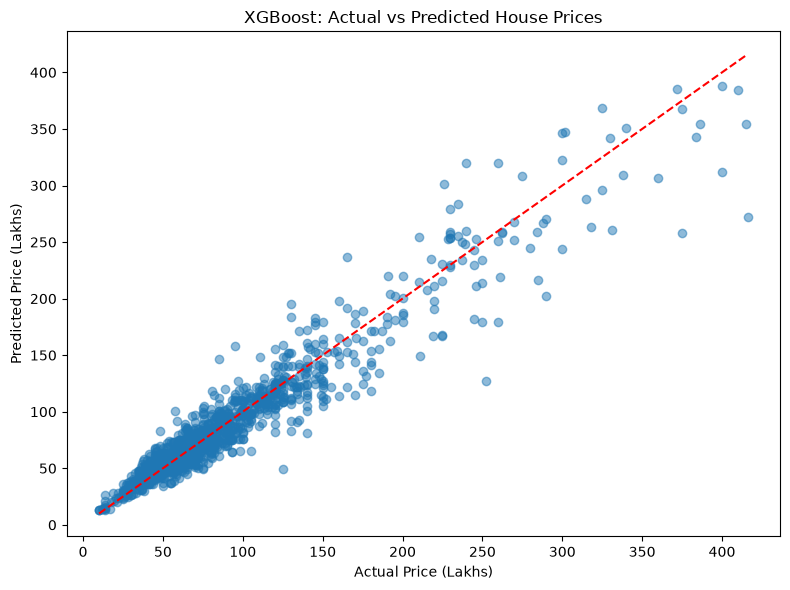

In [18]:
# Generate predictions using the selected pipeline
y_pred = pipeline.predict(X_test)

# Calculate metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.4f} lakhs")
print(f"RMSE: {rmse:.4f} lakhs")
print(f"R2 Score: {r2:.4f}")

# Plot actual versus predicted prices
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")
plt.title("XGBoost: Actual vs Predicted House Prices")
plt.tight_layout()
plt.show()

## 9. Save the Final Model

Save the selected XGBoost pipeline, including preprocessing,
so it can be loaded directly by the Streamlit application.

In [19]:
# Create the models directory if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save the complete pipeline
model_path = "../models/house_price_model.pkl"

joblib.dump(pipeline, model_path)

print("Final pipeline saved successfully!")
print("Saved location:", model_path)

Final pipeline saved successfully!
Saved location: ../models/house_price_model.pkl


## 10. Verify the Saved Model

Load the saved pipeline and test it on one sample
to confirm that it can make predictions.

In [20]:
# Load the saved pipeline
loaded_pipeline = joblib.load(
    "../models/house_price_model.pkl"
)

# Select one test record
sample_house = X_test.iloc[[0]]

# Predict its price
predicted_price = loaded_pipeline.predict(sample_house)[0]

print(f"Predicted price: ₹{predicted_price:.2f} lakhs")
print(f"Actual price: ₹{y_test.iloc[0]:.2f} lakhs")

Predicted price: ₹67.76 lakhs
Actual price: ₹50.30 lakhs
